# Import ও data load

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

DATA_PATH = "../data/"

wallets_features = pd.read_csv(DATA_PATH + "wallets_features.csv")
wallets_classes = pd.read_csv(DATA_PATH + "wallets_classes.csv")

addr_addr = pd.read_csv(DATA_PATH + "AddrAddr_edgelist.csv")
addr_tx = pd.read_csv(DATA_PATH + "AddrTx_edgelist.csv")
tx_addr = pd.read_csv(DATA_PATH + "TxAddr_edgelist.csv")

print("Data loaded successfully")

Data loaded successfully


# Basic shape

In [20]:
datasets = {
    "wallets_features": wallets_features,
    "wallets_classes": wallets_classes,
    "AddrAddr_edgelist": addr_addr,
    "AddrTx_edgelist": addr_tx,
    "TxAddr_edgelist": tx_addr
}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]:,} rows × {df.shape[1]} columns")

wallets_features: 1,268,260 rows × 57 columns
wallets_classes: 822,942 rows × 2 columns
AddrAddr_edgelist: 2,868,964 rows × 2 columns
AddrTx_edgelist: 477,117 rows × 2 columns
TxAddr_edgelist: 837,124 rows × 2 columns


#  Column names

In [21]:
print("Wallet feature columns:")
print(wallets_features.columns.tolist())

print("\nWallet class columns:")
print(wallets_classes.columns.tolist())

print("\nAddr-Addr edge columns:")
print(addr_addr.columns.tolist())

Wallet feature columns:
['address', 'Time step', 'num_txs_as_sender', 'num_txs_as receiver', 'first_block_appeared_in', 'last_block_appeared_in', 'lifetime_in_blocks', 'total_txs', 'first_sent_block', 'first_received_block', 'num_timesteps_appeared_in', 'btc_transacted_total', 'btc_transacted_min', 'btc_transacted_max', 'btc_transacted_mean', 'btc_transacted_median', 'btc_sent_total', 'btc_sent_min', 'btc_sent_max', 'btc_sent_mean', 'btc_sent_median', 'btc_received_total', 'btc_received_min', 'btc_received_max', 'btc_received_mean', 'btc_received_median', 'fees_total', 'fees_min', 'fees_max', 'fees_mean', 'fees_median', 'fees_as_share_total', 'fees_as_share_min', 'fees_as_share_max', 'fees_as_share_mean', 'fees_as_share_median', 'blocks_btwn_txs_total', 'blocks_btwn_txs_min', 'blocks_btwn_txs_max', 'blocks_btwn_txs_mean', 'blocks_btwn_txs_median', 'blocks_btwn_input_txs_total', 'blocks_btwn_input_txs_min', 'blocks_btwn_input_txs_max', 'blocks_btwn_input_txs_mean', 'blocks_btwn_input_tx

#  Sample data

In [22]:
wallets_features.head()

,address,Time step,num_txs_as_sender,num_txs_as receiver,first_block_appeared_in,last_block_appeared_in,lifetime_in_blocks,total_txs,first_sent_block,first_received_block,...,blocks_btwn_output_txs_min,blocks_btwn_output_txs_max,blocks_btwn_output_txs_mean,blocks_btwn_output_txs_median,num_addr_transacted_multiple,transacted_w_address_total,transacted_w_address_min,transacted_w_address_max,transacted_w_address_mean,transacted_w_address_median
0,111112TykSw72ztDN2WJger4cynzWYC5w,25,0.0,1.0,439586.0,439586.0,0.0,1.0,0.0,439586.0,...,0.0,0.0,0.000000,0.0,0.0,24.0,1.0,1.0,1.0,1.0
1,1111DAYXhoxZx2tsRnzimfozo783x1yC2,25,0.0,8.0,439589.0,485959.0,46370.0,8.0,0.0,439589.0,...,0.0,20164.0,6624.285714,8060.0,0.0,8.0,1.0,1.0,1.0,1.0
2,1111DAYXhoxZx2tsRnzimfozo783x1yC2,29,0.0,8.0,439589.0,485959.0,46370.0,8.0,0.0,439589.0,...,0.0,20164.0,6624.285714,8060.0,0.0,8.0,1.0,1.0,1.0,1.0
3,1111DAYXhoxZx2tsRnzimfozo783x1yC2,39,0.0,8.0,439589.0,485959.0,46370.0,8.0,0.0,439589.0,...,0.0,20164.0,6624.285714,8060.0,0.0,8.0,1.0,1.0,1.0,1.0
4,1111DAYXhoxZx2tsRnzimfozo783x1yC2,39,0.0,8.0,439589.0,485959.0,46370.0,8.0,0.0,439589.0,...,0.0,20164.0,6624.285714,8060.0,0.0,8.0,1.0,1.0,1.0,1.0


In [23]:
wallets_classes.head()

,address,class
0,111112TykSw72ztDN2WJger4cynzWYC5w,2
1,1111DAYXhoxZx2tsRnzimfozo783x1yC2,3
2,1111VHuXEzHaRCgXbVwojtaP7Co3QABb,2
3,111218KKkh1JJFRHbwM16AwCiVCc4m7he1,3
4,1115LWW3xsD9jT9VRY7viCN9S34RVAAuA,2


In [24]:
addr_addr.head()

,input_address,output_address
0,14YRXHHof4BY1TVxN5FqYPcEdpmXiYT78a,1GASxu5nMntiRKdVtTVRvEbP965G51bhHH
1,14YRXHHof4BY1TVxN5FqYPcEdpmXiYT78a,14YRXHHof4BY1TVxN5FqYPcEdpmXiYT78a
2,13Lhad3SAmu2vqYg2dxbNcxH7LE77kJu2w,1GFdrdgtG34GChM8SMpMwcXFc4nYbH1A5G
3,1MAQQZn7EHP6J3erXByCciFiVcgS8ZhWqz,19q57SeCEzTnWrWVXA43nZzhSiXkYggh7c
4,1MAQQZn7EHP6J3erXByCciFiVcgS8ZhWqz,1Kk1NVYnCE8ALXDhgMM6HqTt1jDSvi6QBA


# Class distribution

In [25]:
class_counts = wallets_classes["class"].value_counts().sort_index()
class_percent = wallets_classes["class"].value_counts(normalize=True).sort_index() * 100

class_summary = pd.DataFrame({
    "count": class_counts,
    "percentage": class_percent.round(2)
})

class_summary

,count,percentage
class,,
1,14266,1.73
2,251088,30.51
3,557588,67.76


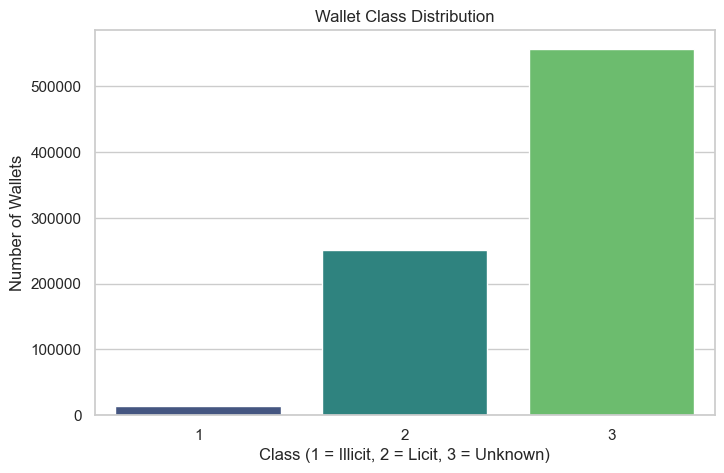

In [26]:
plt.figure(figsize=(8, 5))
sns.countplot(x="class", data=wallets_classes, palette="viridis")
plt.title("Wallet Class Distribution")
plt.xlabel("Class (1 = Illicit, 2 = Licit, 3 = Unknown)")
plt.ylabel("Number of Wallets")
plt.show()

#  Missing values

In [27]:
missing_features = wallets_features.isnull().sum()
missing_features = missing_features[missing_features > 0].sort_values(ascending=False)

if len(missing_features) == 0:
    print("No missing values found in wallets_features.csv")
else:
    print(missing_features)

No missing values found in wallets_features.csv


In [28]:
print("Missing values in wallets_classes:")
print(wallets_classes.isnull().sum())

print("\nMissing values in edge files:")
print("Addr-Addr:", addr_addr.isnull().sum().sum())
print("Addr-Tx:", addr_tx.isnull().sum().sum())
print("Tx-Addr:", tx_addr.isnull().sum().sum())

Missing values in wallets_classes:
address    0
class      0
dtype: int64

Missing values in edge files:
Addr-Addr: 0
Addr-Tx: 0
Tx-Addr: 0


# Duplicate check

In [29]:
print("Duplicate rows:")
print("wallets_features:", wallets_features.duplicated().sum())
print("wallets_classes:", wallets_classes.duplicated().sum())
print("Addr-Addr edges:", addr_addr.duplicated().sum())

Duplicate rows:
wallets_features: 347569
wallets_classes: 0
Addr-Addr edges: 84620


#  Feature statistics


In [30]:
feature_cols = [col for col in wallets_features.columns 
                if col not in ["address", "time_step"]]

print(f"Total feature columns: {len(feature_cols)}")

wallets_features[feature_cols].describe().T.head(20)

Total feature columns: 56


,count,mean,std,min,25%,50%,75%,max
Time step,1268260.0,24.026708,15.049614,1.0,10.000000,23.000000,38.000000,49.000000
num_txs_as_sender,1268260.0,12.700380,88.672574,0.0,0.000000,1.000000,1.000000,1453.000000
num_txs_as receiver,1268260.0,6.566587,45.825422,0.0,1.000000,1.000000,1.000000,548.000000
first_block_appeared_in,1268260.0,434992.480395,30941.598656,391200.0,405321.000000,431529.000000,463777.000000,487975.000000
last_block_appeared_in,1268260.0,440748.706196,30564.465158,391200.0,411363.000000,439589.000000,469828.000000,487975.000000
lifetime_in_blocks,1268260.0,5756.225801,16905.687625,0.0,0.000000,0.000000,5.000000,96775.000000
total_txs,1268260.0,19.266962,116.423712,1.0,1.000000,2.000000,2.000000,1471.000000
first_sent_block,1268260.0,258239.879048,214962.835050,0.0,0.000000,397257.000000,441606.000000,487975.000000
first_received_block,1268260.0,361634.205947,164693.333071,0.0,395232.000000,419429.000000,459747.000000,487975.000000
num_timesteps_appeared_in,1268260.0,1.871110,3.898093,1.0,1.000000,1.000000,1.000000,47.000000


# Feature distribution

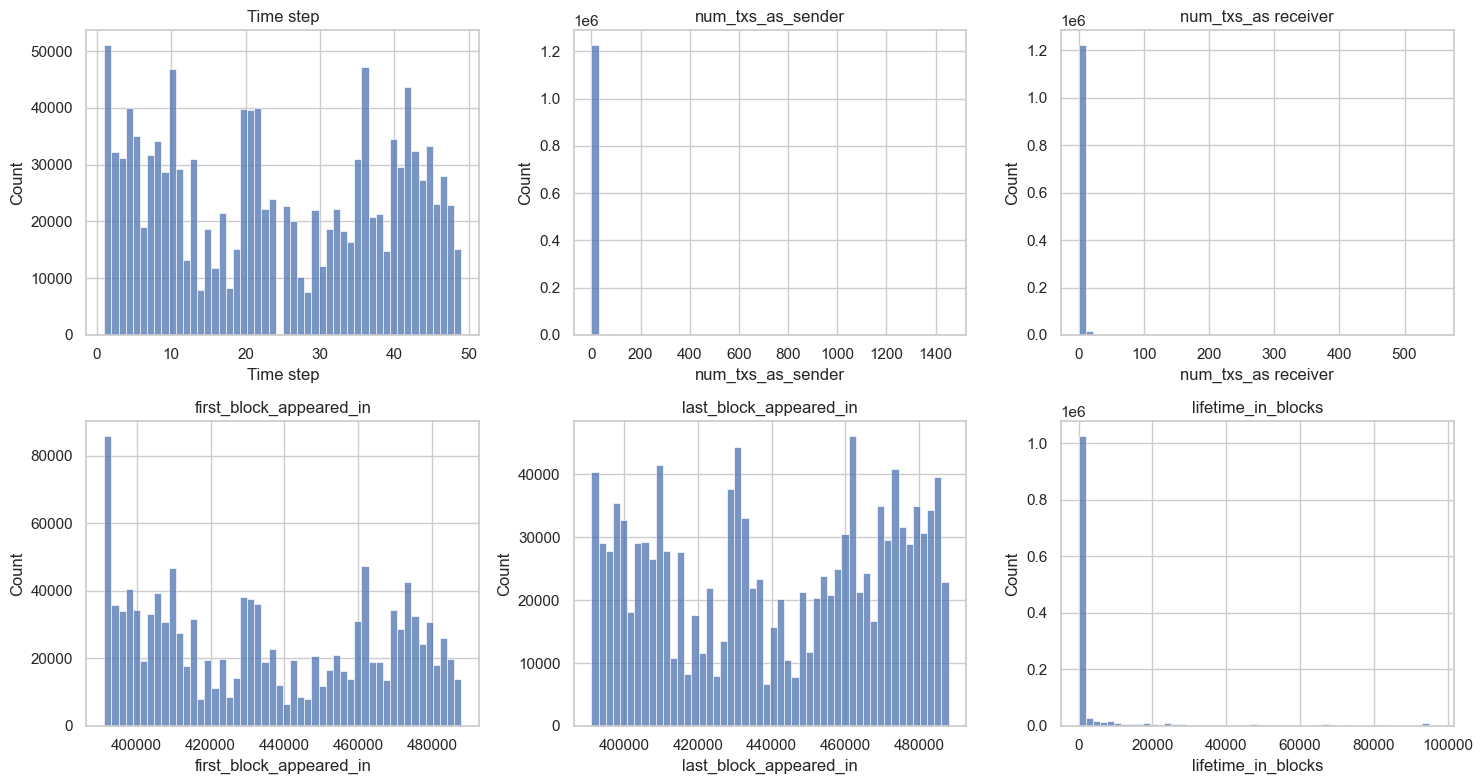

In [31]:
sample_features = feature_cols[:6]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, col in enumerate(sample_features):
    row, col_pos = divmod(i, 3)
    sns.histplot(wallets_features[col], bins=50, ax=axes[row, col_pos])
    axes[row, col_pos].set_title(col)

plt.tight_layout()
plt.show()

#  Time-step analysis

In [32]:
if "time_step" in wallets_features.columns:
    time_counts = wallets_features["time_step"].value_counts().sort_index()

    plt.figure(figsize=(12, 5))
    time_counts.plot(kind="bar")
    plt.title("Number of Wallet Records per Time Step")
    plt.xlabel("Time Step")
    plt.ylabel("Number of Records")
    plt.tight_layout()
    plt.show()
else:
    print("time_step column not found")

time_step column not found


# Merge features ও labels

In [33]:
wallet_df = wallets_features.merge(
    wallets_classes,
    on="address",
    how="left"
)

print("Merged dataset shape:", wallet_df.shape)
wallet_df.head()

Merged dataset shape: (1268260, 58)


,address,Time step,num_txs_as_sender,num_txs_as receiver,first_block_appeared_in,last_block_appeared_in,lifetime_in_blocks,total_txs,first_sent_block,first_received_block,...,blocks_btwn_output_txs_max,blocks_btwn_output_txs_mean,blocks_btwn_output_txs_median,num_addr_transacted_multiple,transacted_w_address_total,transacted_w_address_min,transacted_w_address_max,transacted_w_address_mean,transacted_w_address_median,class
0,111112TykSw72ztDN2WJger4cynzWYC5w,25,0.0,1.0,439586.0,439586.0,0.0,1.0,0.0,439586.0,...,0.0,0.000000,0.0,0.0,24.0,1.0,1.0,1.0,1.0,2
1,1111DAYXhoxZx2tsRnzimfozo783x1yC2,25,0.0,8.0,439589.0,485959.0,46370.0,8.0,0.0,439589.0,...,20164.0,6624.285714,8060.0,0.0,8.0,1.0,1.0,1.0,1.0,3
2,1111DAYXhoxZx2tsRnzimfozo783x1yC2,29,0.0,8.0,439589.0,485959.0,46370.0,8.0,0.0,439589.0,...,20164.0,6624.285714,8060.0,0.0,8.0,1.0,1.0,1.0,1.0,3
3,1111DAYXhoxZx2tsRnzimfozo783x1yC2,39,0.0,8.0,439589.0,485959.0,46370.0,8.0,0.0,439589.0,...,20164.0,6624.285714,8060.0,0.0,8.0,1.0,1.0,1.0,1.0,3
4,1111DAYXhoxZx2tsRnzimfozo783x1yC2,39,0.0,8.0,439589.0,485959.0,46370.0,8.0,0.0,439589.0,...,20164.0,6624.285714,8060.0,0.0,8.0,1.0,1.0,1.0,1.0,3


# Class-wise feature comparison

Labeled wallets only:
class
2    338871
1     28601
Name: count, dtype: int64


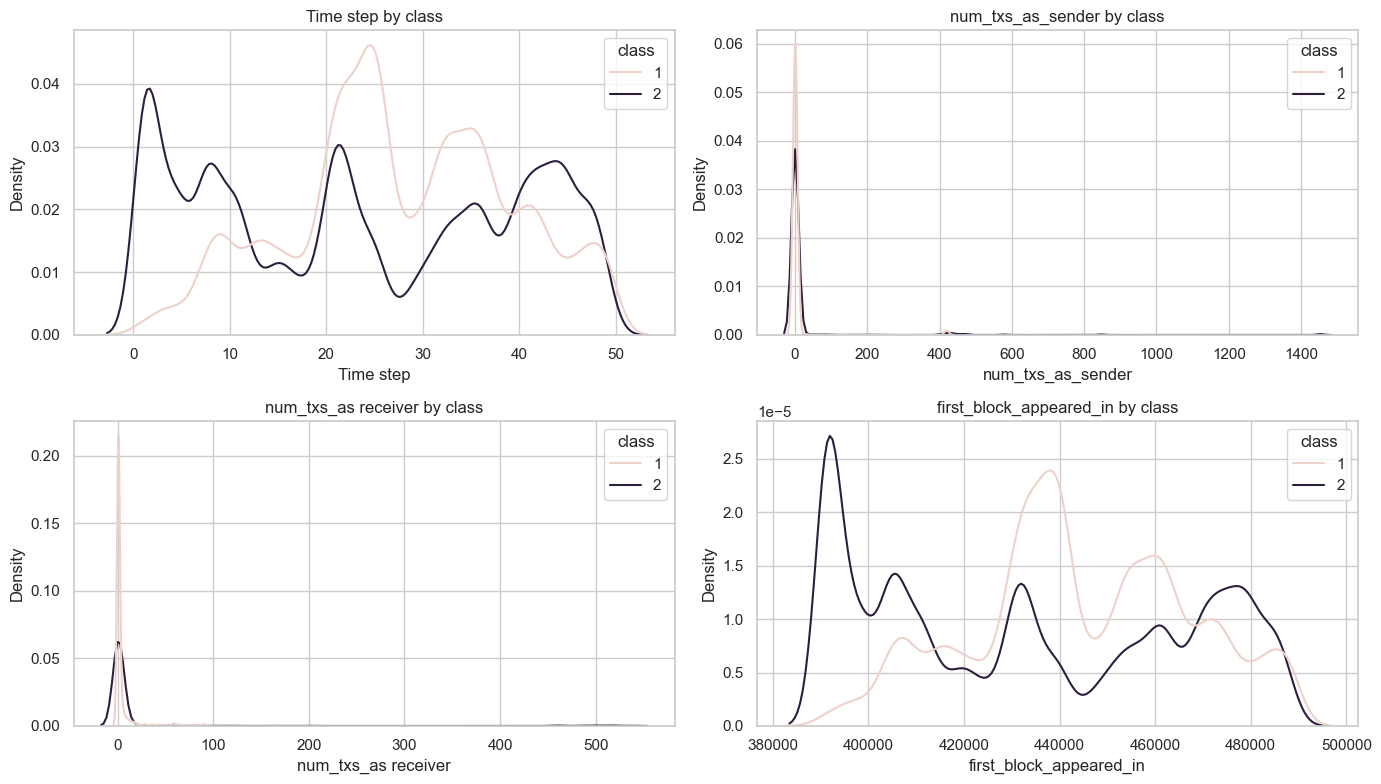

In [34]:
labeled_df = wallet_df[wallet_df["class"].isin([1, 2])].copy()

print("Labeled wallets only:")
print(labeled_df["class"].value_counts())

compare_features = feature_cols[:4]

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for i, col in enumerate(compare_features):
    row, col_pos = divmod(i, 2)
    sns.kdeplot(
        data=labeled_df,
        x=col,
        hue="class",
        common_norm=False,
        ax=axes[row, col_pos]
    )
    axes[row, col_pos].set_title(f"{col} by class")

plt.tight_layout()
plt.show()

# Graph edge analysis

In [35]:
print("Addr-Addr edge statistics")
print("Unique source addresses:", addr_addr.iloc[:, 0].nunique())
print("Unique destination addresses:", addr_addr.iloc[:, 1].nunique())
print("Total edges:", len(addr_addr))

Addr-Addr edge statistics
Unique source addresses: 400212
Unique destination addresses: 641043
Total edges: 2868964


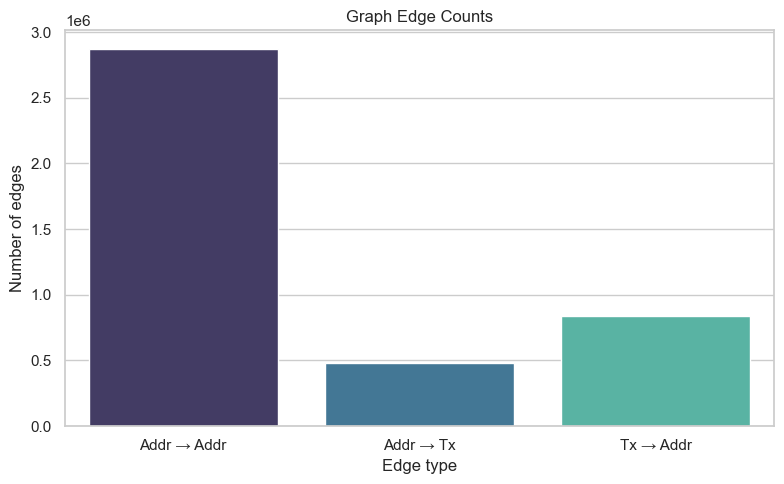

In [36]:
edge_summary = pd.DataFrame({
    "Edge type": ["Addr → Addr", "Addr → Tx", "Tx → Addr"],
    "Number of edges": [len(addr_addr), len(addr_tx), len(tx_addr)]
})

plt.figure(figsize=(8, 5))
sns.barplot(x="Edge type", y="Number of edges", data=edge_summary, palette="mako")
plt.title("Graph Edge Counts")
plt.tight_layout()
plt.show()

# Save cleaned EDA summary

In [37]:
import os

os.makedirs("../outputs/results", exist_ok=True)

class_summary.to_csv("../outputs/results/class_distribution.csv")
wallet_df.to_csv("../outputs/results/wallet_features_with_labels.csv", index=False)

print("EDA summary saved successfully")

EDA summary saved successfully
